In [2]:
!pip install numpy
!pip install matplotlib
!pip install pandas
!pip install scipy
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

In [3]:
cols = [
    "burst",        # Burst counter
    "ensemble",     # Ensemble counter (1-65536)
    "w",            # Velocity Beam1|X|East (m/s) orginally u renamed to w to reflect vertical velocities
    "u",            # Velocity Beam2|Y|North (m/s) originally v now renamed to u to reflect crossh shore velocities
    "v",            # Velocity Beam3|Z|Up (m/s) orginally w now renamed to v to reflect alongshore velocities
    "amp1",         # Amplitude Beam1 (counts)
    "amp2",         # Amplitude Beam2 (counts)
    "amp3",         # Amplitude Beam3 (counts)
    "snr1",         # SNR Beam1 (dB)
    "snr2",         # SNR Beam2 (dB)
    "snr3",         # SNR Beam3 (dB)
    "corr1",        # Correlation Beam1 (%)
    "corr2",        # Correlation Beam2 (%)
    "corr3",        # Correlation Beam3 (%)
    "pressure",     # Pressure (dbar)
    "analog1",      # Analog input 1
    "analog2",      # Analog input 2
    "checksum",     # Checksum (1 = failed)
]

df = pd.read_csv("SSC01.dat", sep=r"\s+", header=None, names=cols)

In [4]:
df["t"] = df.index / 16
start = pd.Timestamp("2026-09-29 06:00:00")
df["time"] = start + pd.to_timedelta(df["t"], unit="s")

In [5]:
DAY = start.strftime("%Y-%m-%d")   


manoeuvres = {
    "A1-11": "07:40:22",
    "A1-12": "07:46:51",
    "A2-11": "07:57:17",
    "A2-12": "08:02:11",
    "A3-11": "08:07:25",
    "A3-12": "08:12:08",
    "B-11":  "08:17:53",
    "B-12":  "08:23:40",
    "C-11":  "08:40:40",
    "C-12":  "08:45:57",
    "E-11":  "08:51:35",
    "E-12":  "08:57:08",
    
    "A1-21": "09:02:35",
    "A1-22": "09:07:47",
    "A2-21": "09:19:14",
    "A2-22": "09:29:27",
    "A3-21": "09:29:27",
    "A3-22": "09:35:17",
    "B-21":  "09:42:33",
    "B-22":  "09:49:34",
    "C-21":  "09:55:04",
    "C-22":  "09:58:54",
    "E-21":  "10:02:51",
    "E-22":  "10:06:45",

    "A1-31": "10:15:16",
    "A2-31": "10:17:03",
    "A3-31": "10:19:05",
    "B-31":  "10:22:36",
    "C-31":  "10:25:25",
    "E-31":  "10:31:33",
    "D-31":  "10:37:55",
    "D-32":  "10:41:15",
    "D-33":  "10:44:33",
    "F-31":  ["10:47:49", "10:48:31","10:49:06", "10:49:44"], 
    "F-32":  ["10:52:31", "10:53:11","10:53:57", "10:53:41"],  
    "F-33":  ["10:58:47", "10:59:37", "11:00:27", "11:01:18"],

    "A1-41": "07:52:21",
    "B-41":  "08:29:40",
    "B-42":  "08:36:05",
    "A2-41": "09:24:16",
    "E-41": "10:10:30",
    "C-41": "10:28:22",
    "A1-41": "10:34:17",
    "F-41": ["11:04:24", "11:05:04", "11:05:41", "11:06:18"]
    

}

def select(ids):
    """Accepts one id ("B-11"), a list (["B-11", "B-12"]) or a whole type ("B")."""
    if isinstance(ids, str):
        ids = [ids]
    out = []
    for i in ids:
        if i in manoeuvres:
            out.append(i)
        else:
            matches = [k for k in manoeuvres if k.split("-")[0] == i]
            if not matches:
                raise KeyError(f"Unknown manoeuvre or type: {i}")
            out += matches
    return out

def plot_overlay(data, ids, before=120, after=120, col="analog1"):
    if ids[0].startswith("F"):
        
        
        fig, ax = plt.subplots(figsize=(10, 5))
        for name in select(ids):
                t = manoeuvres[name]
                if isinstance(t, str):          # F-31, F-32, F-33 are a single time
                    t = [t]
                times = [pd.Timestamp(f"{DAY} {x}") for x in t]
                c = times[0]
                win = data[(data["time"] >= times[0] - pd.Timedelta(seconds=before)) &
                        (data["time"] <= times[-1] + pd.Timedelta(seconds=after))]
                if win.empty:
                    print(f"No data around {name} ({c:%H:%M:%S}), skipped")
                    continue
                rel_t = (win["time"] - c).dt.total_seconds()
                ax.plot(rel_t, win[col], lw=0.8, label=f"{name}  ({c:%H:%M:%S})")

                i = 1
                for x in times:

                    ax.axvline((x - c).total_seconds(), color="k", ls="--", lw=0.8)

                    ax.text((x - c).total_seconds(), 0.95, f"pass {i}", transform=ax.get_xaxis_transform(), ha="center", fontsize=10, color = "red", 
                            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="k"))
                    i += 1

        ax.set_xlabel("Time relative to boat passage (s)")
        ax.set_ylabel(col)
        ax.set_title(f"{col}: {before} s before to {after} s after passage")
        ax.grid(True, alpha=0.3)
        ax.legend()
        plt.tight_layout()
        plt.show()

    else:

        fig, ax = plt.subplots(figsize=(10, 5))
        for name in select(ids):
            c = pd.Timestamp(f"{DAY} {manoeuvres[name]}")
            win = data[(data["time"] >= c - pd.Timedelta(seconds=before)) &
                    (data["time"] <= c + pd.Timedelta(seconds=after))]
            if win.empty:
                print(f"No data around {name} ({c:%H:%M:%S}), skipped")
                continue
            rel_t = (win["time"] - c).dt.total_seconds()
            ax.plot(rel_t, win[col], lw=0.8, label=f"{name}  ({c:%H:%M:%S})")
        ax.axvline(0, color="k", ls="--", lw=0.8)
        ax.set_xlabel("Time relative to boat passage (s)")
        ax.set_ylabel(col)
        ax.set_title(f"{col}: {before} s before to {after} s after passage")
        ax.grid(True, alpha=0.3)
        ax.legend()
        plt.tight_layout()
        plt.show()

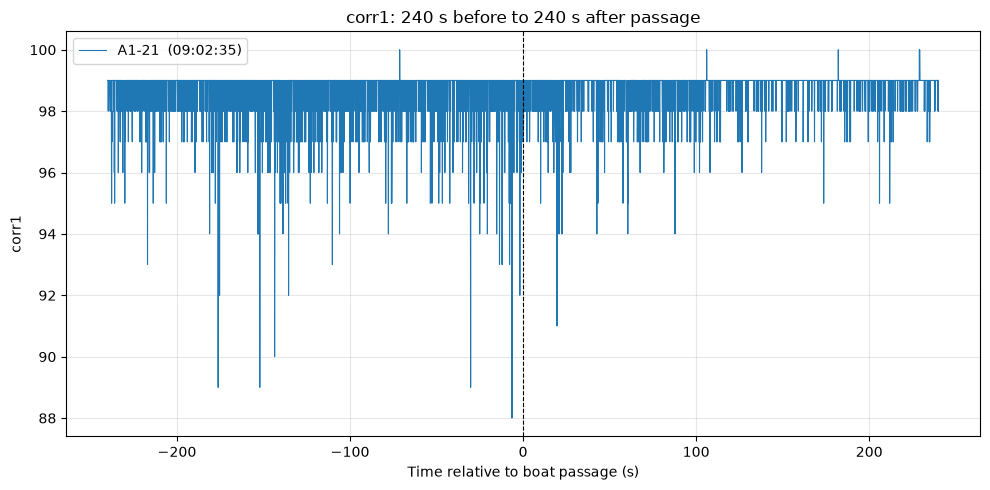

In [6]:
plot_overlay(df, "A1-21", before = 240, after = 240, col = "corr1")                       # one manoeuvre

#plot_overlay(df, "B-21", before = 1000, after = 1000, col = "v")    
#plot_overlay(df, "B-21", before = 120, after = 120, col = "w")                       # one manoeuvre
                   # one manoeuvre
#plot_overlay(df, ["B-11", "B-12"], col="analog")    # a few
#plot_overlay(df, "B", col="analog1")                 # every B manoeuvre
#plot_overlay(df, "A1")                         # every A1 manoeuvre

### Pressure Sensor Data

In [7]:
# print(df['pressure']) 
# print(df['time'])

In [8]:
pressure = df[['time','pressure']]  # in bar
print(pressure)

                             time  pressure
0      2026-09-29 06:00:00.000000     0.212
1      2026-09-29 06:00:00.062500     0.211
2      2026-09-29 06:00:00.125000     0.214
3      2026-09-29 06:00:00.187500     0.211
4      2026-09-29 06:00:00.250000     0.214
...                           ...       ...
360096 2026-09-29 12:15:06.000000     0.834
360097 2026-09-29 12:15:06.062500     0.807
360098 2026-09-29 12:15:06.125000     0.789
360099 2026-09-29 12:15:06.187500     0.766
360100 2026-09-29 12:15:06.250000     0.746

[360101 rows x 2 columns]


In [9]:
pressure["time"] = pd.to_datetime(pressure["time"])

target_start = pd.Timestamp("2026-09-29 07:30:00")
result_start = pressure.loc[pressure["time"].eq(target_start)]
# print(result_start)

target_end = pd.Timestamp("2026-09-29 11:25:00")
result_end = pressure.loc[pressure["time"].eq(target_end)]
# print(result_end)

Text(0.5, 1.0, 'Pressure Timesiers')

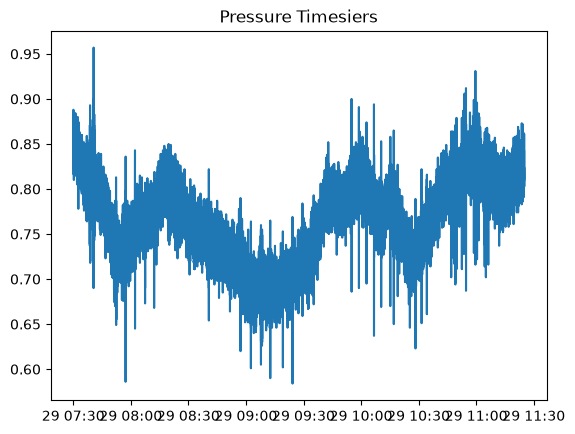

In [10]:
# df['pressure'].plot()
plt.plot(pressure['time'][86400:312000], pressure['pressure'][86400:312000]);
plt.title('Pressure Timesiers')

In [11]:
sampling_rate = 16              # Hz
sensor_height = 0.395 + 0.06   # m above the bed
rho = 1025                      # density of seawater in kg/m^3
g = 9.81                        # acceleration due to gravity in m/s^2

press_pa = pressure["pressure"] * 1e4  # dbar to Pa
depth = press_pa / (rho * g) + sensor_height

In [12]:
from scipy.signal import butter, sosfiltfilt

def signals_filter(data, cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    sos = butter(order, normal_cutoff, btype="low", output="sos")
    return sosfiltfilt(sos, data)

In [13]:
start_idx = 86400
end_idx = 312000

depth_segment = depth.iloc[start_idx:end_idx]
time_segment = pressure["time"].iloc[start_idx:end_idx]

cutoff_period = 60       # seconds; separates waves from slower water-level changes
cutoff_freq = 1 / cutoff_period
water_level_trend = signals_filter(
    depth_segment.to_numpy(),
    cutoff_freq,
    sampling_rate,
)
wave_sig = depth_segment.to_numpy() - water_level_trend

H_s = 4 * np.std(wave_sig)
d_average = np.mean(depth_segment)

print(f"H_s = {H_s:.3f} m")
print(f"Average depth = {d_average:.3f} m")

H_s = 0.065 m
Average depth = 1.217 m


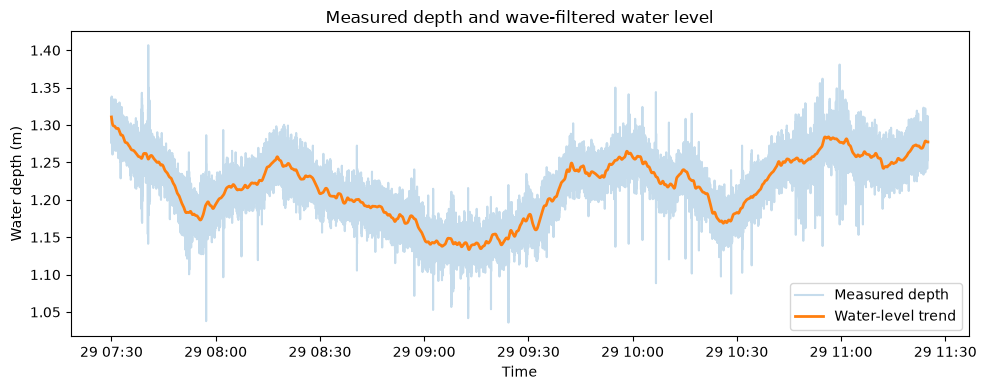

In [14]:
plt.figure(figsize=(10, 4))
plt.plot(time_segment, depth_segment, alpha=0.25, label="Measured depth")
plt.plot(time_segment, water_level_trend, linewidth=2, label="Water-level trend")
plt.xlabel("Time")
plt.ylabel("Water depth (m)")
plt.title("Measured depth and wave-filtered water level")
plt.legend()
plt.tight_layout()
plt.show()

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=cb8feeb3-afee-4b20-ab89-f0abd9348b44' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>